# Homework 1
Due Wednesday Sep 23, 11:59pm (EST)

Rachel Liu

Teammates: Constance Chen

## Part I. The Housing Prices
Based off of d2l.ai textbook sections 5.7. Predicting House Prices on Kaggle

In [3]:
%matplotlib inline
import pandas as pd
import matplotlib.pyplot as plt
import math
import torch
from torch import nn
from d2l import torch as d2l


In [4]:
class KaggleHouse(d2l.DataModule):
    def __init__(self, batch_size, train=None, val=None):
        super().__init__()
        self.save_hyperparameters()
        if self.train is None:
            self.raw_train = pd.read_csv(d2l.download(
                d2l.DATA_URL + 'kaggle_house_pred_train.csv', self.root,
                sha1_hash='585e9cc93e70b39160e7921475f9bcd7d31219ce'))
            self.raw_val = pd.read_csv(d2l.download(
                d2l.DATA_URL + 'kaggle_house_pred_test.csv', self.root,
                sha1_hash='fa19780a7b011d9b009e8bff8e99922a8ee2eb90'))

In [5]:
# The training dataset includes 1460 examples, 80 features, and one label, while the validation data contains 1459 examples and 80 features.
data = KaggleHouse(batch_size=64)
print(data.raw_train.shape)
print(data.raw_val.shape)

(1460, 81)
(1459, 80)


2. Give 3 examples of continuous and categorical features in the dataset; choose one feature of each type and plot the histogram to illustrate the distribution.

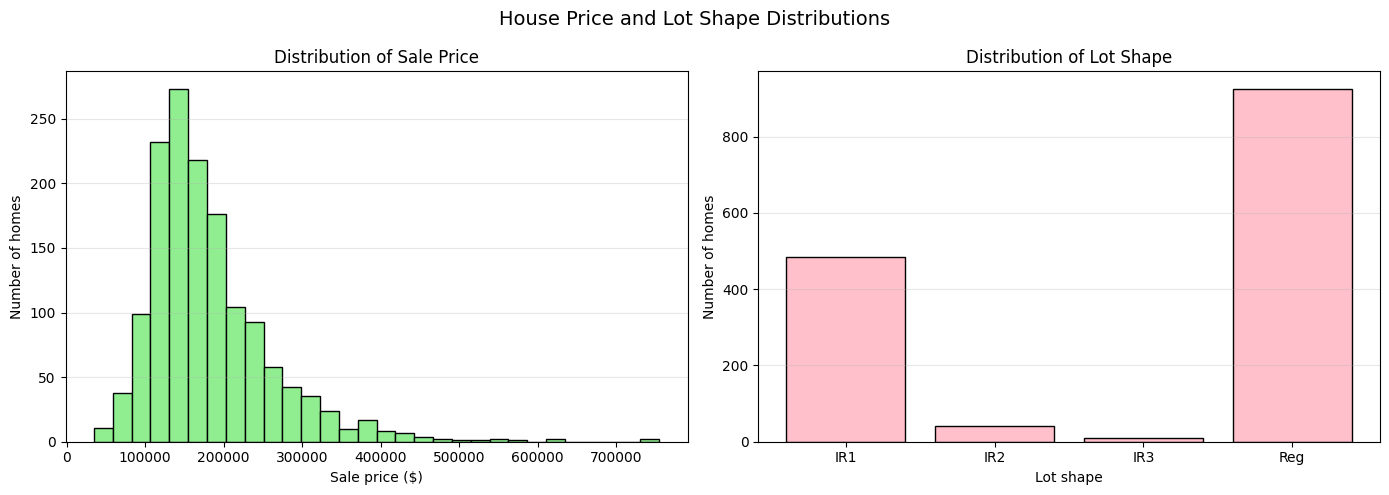

In [6]:
# I plotted SalePrice and LotShape side by side using matplotlib.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(
    data.raw_train["SalePrice"].dropna(),
    bins=30,
    color="lightgreen",
    edgecolor="black",
)
axes[0].set_title("Distribution of Sale Price")
axes[0].set_xlabel("Sale price ($)")
axes[0].set_ylabel("Number of homes")
axes[0].grid(axis="y", alpha=0.3)

lot_shape_counts = data.raw_train["LotShape"].value_counts().sort_index()
axes[1].bar(
    lot_shape_counts.index,
    lot_shape_counts.values,
    color="pink",
    edgecolor="black",
)
axes[1].set_title("Distribution of Lot Shape")
axes[1].set_xlabel("Lot shape")
axes[1].set_ylabel("Number of homes")
axes[1].grid(axis="y", alpha=0.3)

fig.suptitle("House Price and Lot Shape Distributions", fontsize=14)
fig.tight_layout()
plt.show()

3. Pre-process your data, explain your pre-processing steps, and the reasons why you need them. (Hint: data pre-processing steps can include but are not restricted to: dealing with missing values, normalizing numerical values, dealing with categorical values etc.)

In [7]:
# First we look at the first four and final two features as well as the label (SalePrice) from the first four examples.
# We can see that the first feature is the identifier which helps model termine each training example but does not carry any information for prediction purposes. Therefor we will remove it. 
# We also need to preprocess the wide variety of data types before we start modeling.
# Such as
## Numerical features: Replace all missing values by the feature's mean. Then we standardize the data by rescaling features to zero mean and unit variance
## Categorical features: Replace discrete features by one-hot encoding
print(data.raw_train.iloc[:4, [0, 1, 2, 3, -3, -2, -1]])

   Id  MSSubClass MSZoning  LotFrontage SaleType SaleCondition  SalePrice
0   1          60       RL         65.0       WD        Normal     208500
1   2          20       RL         80.0       WD        Normal     181500
2   3          60       RL         68.0       WD        Normal     223500
3   4          70       RL         60.0       WD       Abnorml     140000


In [8]:
@d2l.add_to_class(KaggleHouse)
def preprocess(self):
    # Remove the ID and label columns
    label = 'SalePrice'
    features = pd.concat(
        (self.raw_train.drop(columns=['Id', label]),
         self.raw_val.drop(columns=['Id'])))
    # Standardize numerical columns
    numeric_features = features.dtypes[features.dtypes!='object'].index
    features[numeric_features] = features[numeric_features].apply(
        lambda x: (x - x.mean()) / (x.std()))
    # Replace NAN numerical features by 0
    features[numeric_features] = features[numeric_features].fillna(0)
    # Replace discrete features by one-hot encoding
    features = pd.get_dummies(features, dummy_na=True)
    # Save preprocessed features
    self.train = features[:self.raw_train.shape[0]].copy()
    self.train[label] = self.raw_train[label]
    self.val = features[self.raw_train.shape[0]:].copy()

In [9]:
# We can see here that this step increases the number of features from 79 to 331 due to OHE. 
data.preprocess()
data.train.shape

(1460, 331)

4. One-hot encoding (OHE) using pandas 

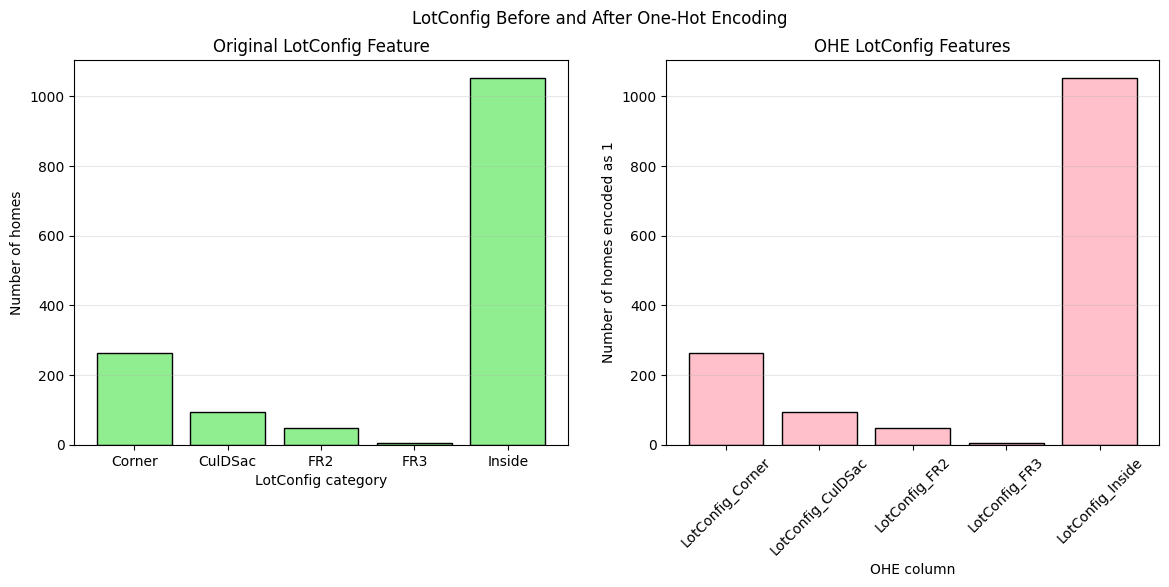

In [10]:
# OHE the categorical LotConfig feature using pd.get_dummies() which converts each of the 5 categories into its own OHE column with int type [0,1].
lot_config_ohe = pd.get_dummies(
    data.raw_train["LotConfig"],
    prefix="LotConfig",
    dtype=int,
)

# Then, count the original categories and the 1s in each one-hot column.
lot_config_counts = data.raw_train["LotConfig"].value_counts().sort_index()
ohe_counts = lot_config_ohe.sum().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(
    lot_config_counts.index,
    lot_config_counts.values,
    color="lightgreen",
    edgecolor="black",
)
axes[0].set_title("Original LotConfig Feature")
axes[0].set_xlabel("LotConfig category")
axes[0].set_ylabel("Number of homes")
axes[0].grid(axis="y", alpha=0.3)

axes[1].bar(
    ohe_counts.index,
    ohe_counts.values,
    color="pink",
    edgecolor="black",
)
axes[1].set_title("OHE LotConfig Features")
axes[1].set_xlabel("OHE column")
axes[1].set_ylabel("Number of homes encoded as 1")
axes[1].tick_params(axis="x", rotation=45)
axes[1].grid(axis="y", alpha=0.3)

fig.suptitle("LotConfig Before and After One-Hot Encoding")
plt.show()



5. Ordinary Least Squares (OLS)

In [11]:
# When we train a linear model with squared loss, we will not do very good compared to fancier models.
# However, it will be a sanity check to see if there is meaningful info in the data (better than random guessing)
# Also, will be useful to compare this performance against fancier models.
# The code below is from the textbook, I am implementing from scratch in the next cell 
@d2l.add_to_class(KaggleHouse)
def get_dataloader(self, train):
    label = 'SalePrice'
    data = self.train if train else self.val
    if label not in data: return
    get_tensor = lambda x: torch.tensor(x.values.astype(float),
                                      dtype=torch.float32)
    # Logarithm of prices
    tensors = (get_tensor(data.drop(columns=[label])),  # X
               torch.log(get_tensor(data[label])).reshape((-1, 1)))  # Y
    return self.get_tensorloader(tensors, train)

In [12]:
# OLS from scratch using the previously defined preprocessing function.
# As a reminder, data.preprocess() removed Id, separates SalePrice, standardizes numerical features, fills missing numerical values, OHE categorical features.
data.preprocess()

# This stores the processed df and identifies the target column
processed_train = data.train
label = "SalePrice"

# Remove SalePrice from the input features, as well as constant and duplicate features.
X_frame = processed_train.drop(columns=[label])
X_frame = X_frame.loc[:, X_frame.nunique(dropna=False) > 1]
X_frame = X_frame.T.drop_duplicates().T

# Converts processed features into Python list of lists, where the [1.0] is the intecept column. 
X = [[1.0] + [float(value) for value in row]
     for row in X_frame.values.tolist()]
# Converts the actual SalePrice values into a Python list.
y = [float(value) for value in processed_train[label]]

# This stores dimensions of the design matrix
number_of_rows = len(X)
number_of_columns = len(X[0])

# Modified Gram-Schmidt QR decomposition using plain Python.
q_vectors = []              # orthogonal unit vectors
independent_columns = []    # columns that contain new information
r_values = []               # coefficients used to reconstruct matrix

# [Do I need to dot product manually?] Defines vector dot product manually 
def dot(left, right):
    return sum(left[index] * right[index] for index in range(number_of_rows))

# Process each feature column by looping through each column of the design matrix
# Then extracts one column from X and creates a list to store how much this column overlaps with previous independent columns
for column_index in range(number_of_columns):
    vector = [X[row][column_index] for row in range(number_of_rows)]
    projections = []

    # Here, we loop through orthogonal vectors and measure how much current column points in direction of the previous vector
    # This is stored as a projection coefficient
    # Subtract the overlapping part to make the current vector independent from previous vectors 
    for q_vector in q_vectors:
        projection = dot(q_vector, vector)
        projections.append(projection)
        vector = [
            vector[row] - projection * q_vector[row]
            for row in range(number_of_rows)
        ]

    # Here, we calculate the vector's length, normalize it and records that this feature column is independent.  
    norm = math.sqrt(dot(vector, vector))
    if norm > 1e-10:
        q_vectors.append([value / norm for value in vector])
        independent_columns.append(column_index)
        r_values.append(projections + [norm])

# Solve  for the OLS coefficients. R beta = Q^T y by back substitution.
number_of_independent_columns = len(independent_columns)
right_side = [dot(q_vector, y) for q_vector in q_vectors]
beta_independent = [0.0] * number_of_independent_columns

for row in range(number_of_independent_columns - 1, -1, -1):
    value = right_side[row]
    for column in range(row + 1, number_of_independent_columns):
        value -= r_values[column][row] * beta_independent[column]
    beta_independent[row] = value / r_values[row][row]

beta = [0.0] * number_of_columns
for index, column_index in enumerate(independent_columns):
    beta[column_index] = beta_independent[index]

# Here we make predictions by calculating the predicted price for every house through matrix multiplication.
predictions = [
    sum(beta[column] * X[row][column] for column in range(number_of_columns))
    for row in range(number_of_rows)
]

# Here we calculate mean squared error, where lower values indicate smaller prediction errors
mse = sum((actual - predicted) ** 2
          for actual, predicted in zip(y, predictions)) / number_of_rows
mean_price = sum(y) / number_of_rows
# Then we calculate r^2 where a number closer to 1 means the model explains more variation in house prices
r2 = 1 - (
    sum((actual - predicted) ** 2
        for actual, predicted in zip(y, predictions))
    / sum((actual - mean_price) ** 2 for actual in y)
)

print(f"OLS used {len(X_frame.columns)} processed features")
print(f"Training MSE: {mse:,.2f}")
print(f"Training R^2: {r2:.4f}")

OLS used 297 processed features
Training MSE: 421,100,247.40
Training R^2: 0.9332


6. Train the model

In [13]:
# I'm using the k fold method which splices out the ith segment as validation data and returns the rest as training data.
# This function specifically creates k splits and returns the list of all five train/validation splits
def k_fold_data(data, k):
    rets = []
    fold_size = data.train.shape[0] // k
    for j in range(k):
        idx = range(j * fold_size, (j+1) * fold_size)
        rets.append(
            KaggleHouse(
                data.batch_size, 
                data.train.drop(index=idx),
                data.train.loc[idx]
            )
        )
    return rets

In [16]:
# Then we train one model per fold. If k=5 we end up with 5 trained models.
# This code also returns the average validation error when we train K times in the K-fold cross-validation.
def k_fold(trainer, data, k, lr):
    val_loss, models = [], []
    for i, data_fold in enumerate(k_fold_data(data, k)):
        model = d2l.LinearRegression(lr)
        model.board.yscale='log'
        if i != 0: model.board.display = False
        trainer.fit(model, data_fold)
        val_loss.append(float(model.board.data['val_loss'][-1].y))
        models.append(model)
    print(f'average validation log mse = {sum(val_loss)/len(val_loss)}')
    return models

average validation log mse = 0.1775434821844101


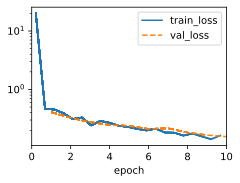

In [17]:
# Now we choose the model by creating a trainer that trains each model for 10 epochs.
# Then, we split the data into five folds, trains five separate linear reg models, use each fold once as validation data, calculates the average validation error, and stores the five models.
trainer = d2l.Trainer(max_epochs=10)
models = k_fold(trainer, data, k=5, lr=0.01)

In [31]:
# Now predict with every model and store the predictions in preds. 
# However the predicts are logarithms of prices so we need to combine predictions into one matrix, convert predictions back to normal dollar prices, and then average the five predictions for each house. This is an "ensemble prediction"
preds = [model(torch.tensor(data.val.values.astype(float), dtype=torch.float32))
         for model in models]
# Taking exponentiation of predictions in the logarithm scale
ensemble_preds = torch.exp(torch.cat(preds, 1)).mean(1)

# This creates the submission file which creates a pandas df with house IDs and predicted sale prices.
submission = pd.DataFrame({'Id':data.raw_val.Id,
                           'SalePrice':ensemble_preds.detach().numpy()})
submission.to_csv('rliu_housing_submission.csv', index=False)

## Part II. The Titanic Disaster
Preprocssing also based off of d2l.ai textbook sections 5.7. Predicting House Prices on Kaggle

1. Download and preprocess the data

In [25]:
import pandas as pd

raw_tit_train = pd.read_csv('titanic/train.csv')
raw_tit_val = pd.read_csv('titanic/test.csv')

print(raw_tit_train.shape)
print(raw_tit_val.shape)
print(raw_tit_train.iloc[:4, [0, 1, 2, 3, -3, -2, -1]])

(891, 12)
(418, 11)
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   

                                                Name     Fare Cabin Embarked  
0                            Braund, Mr. Owen Harris   7.2500   NaN        S  
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  71.2833   C85        C  
2                             Heikkinen, Miss. Laina   7.9250   NaN        S  
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  53.1000  C123        S  


In [32]:
# Preprocessing 
def preprocessTit(raw_train, raw_val):
    # Remove the ID and label columns
    label = 'Survived'
    features = pd.concat(
        (raw_train.drop(columns=['PassengerId', label]),
         raw_val.drop(columns=['PassengerId'])))
    # Standardize numerical columns
    numeric_features = features.dtypes[features.dtypes != 'object'].index
    features[numeric_features] = features[numeric_features].apply(
        lambda x: (x - x.mean()) / (x.std()))
    # Replace NAN numerical features by 0
    features[numeric_features] = features[numeric_features].fillna(0)
    # Replace discrete features by one-hot encoding
    features = pd.get_dummies(features, dummy_na=True)
    # Save preprocessed features
    train = features[:raw_train.shape[0]].copy()
    train[label] = raw_train[label]
    val = features[raw_train.shape[0]:].copy()
    return train, val

In [33]:
train, val = preprocessTit(raw_tit_train, raw_tit_val)
print(train.shape)

(891, 2438)


2. Implement Logistic Regression

In [34]:
from sklearn.linear_model import LogisticRegression

# Separate features and label
X = train.drop(columns=['Survived'])
y = train['Survived']

# Fit logistic regression on all training data
clf = LogisticRegression(max_iter=1000)
clf.fit(X, y)

/Users/leo/Desktop/home/Github Development/2026cornelltech/appliedMachineLearning/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/leo/Desktop/home/Github Development/2026cornelltech/appliedMachineLearning/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/leo/Desktop/home/Github Development/2026cornelltech/appliedMachineLearning/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/leo/Desktop/home/Github Development/2026cornelltech/appliedMachineLearning/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:209: RuntimeWarning: divide by zero encountered in matmul
  norm2_w = weights @ weights if w

LogisticRegression(max_iter=1000)

3. Train classifier, test, and submit results to Kaggle

In [37]:
test_preds = clf.predict(val)

submission = pd.DataFrame({
    'PassengerId': raw_tit_val['PassengerId'],
    'Survived': test_preds
})
submission.to_csv('rliu_titanic_submission.csv', index=False)

/Users/leo/Desktop/home/Github Development/2026cornelltech/appliedMachineLearning/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/leo/Desktop/home/Github Development/2026cornelltech/appliedMachineLearning/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/leo/Desktop/home/Github Development/2026cornelltech/appliedMachineLearning/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
